
# MTA Daily Ridership Analysis

## 1. Business Understanding

### Business Background
The Metropolitan Transportation Authority (MTA) operates public transportation services in New York, including subways, buses, railroads, and other transportation services.

This dataset provides daily ridership and traffic estimates starting from March 2020, allowing us to examine transportation usage and its recovery following the COVID-19 pandemic.

### Business Problem
Understanding how the COVID-19 pandemic affected public transportation usage and how different transportation systems recovered over time.

### Business Objectives
- Analyze daily transportation usage.
- Examine the impact of COVID-19 on ridership.
- Compare recovery across transportation systems.
- Identify monthly, yearly, and weekly trends.
- Evaluate recovery compared with pre-pandemic levels.

### Business Questions
1. Which transportation system has the highest usage?
2. How did COVID-19 affect transportation usage?
3. Which transportation system recovered the fastest?
4. How did transportation usage change between 2020 and 2024?
5. Are weekdays busier than weekends?
6. Which months have the highest transportation usage?
7. Which system is closest to its pre-pandemic level?

### KPIs
- Average Daily Ridership
- Total Estimated Ridership
- Average Recovery Percentage
- Year-over-Year Growth
- Monthly Average Ridership

### Project Scope
Dataset: MTA Daily Ridership  
Tools: Python, Pandas, NumPy, Matplotlib, Seaborn  
Analysis: Data Exploration, Data Cleaning, and Exploratory Data Analysis.


------------------------------------------------------------------------------------------------------------------------------------------


## 2. Data Understanding and Exploratory Data Analysis


In [1]:
import os
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


def find_project_root(start: Path) -> Path:
    """Return the directory that contains the WEEK ONE project folder."""
    for candidate in (start, *start.parents):
        if (candidate / "WEEK ONE" / "python").is_dir() and (
            candidate / "WEEK ONE" / "database"
        ).is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root. Run the notebook from inside the "
        "project or set MTA_PROJECT_ROOT to the directory containing 'WEEK ONE'."
    )


_env_root = os.environ.get("MTA_PROJECT_ROOT")
PROJECT_ROOT = (
    Path(_env_root).expanduser().resolve()
    if _env_root
    else find_project_root(Path.cwd())
)

SOURCE_DATA_PATH = Path(
    os.environ.get(
        "MTA_SOURCE_DATA_PATH",
        PROJECT_ROOT / "WEEK ONE" / "data" / "raw" / "MTA_Daily_Ridership.csv",
    )
).expanduser().resolve()
CLEANED_DATA_PATH = PROJECT_ROOT / "WEEK ONE" / "MTA_Daily_Ridership_Cleaned.csv"
DATABASE_DIR = PROJECT_ROOT / "WEEK ONE" / "database"

CLEANED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
DATABASE_DIR.mkdir(parents=True, exist_ok=True)

if not SOURCE_DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Source dataset not found: {SOURCE_DATA_PATH}. "
        "Place the original MTA export there or set MTA_SOURCE_DATA_PATH."
    )


def display_path(path: Path) -> str:
    """Show project-relative paths when possible, without machine-specific roots."""
    try:
        return path.relative_to(PROJECT_ROOT).as_posix()
    except ValueError:
        return path.as_posix()


print(f"Project root: {PROJECT_ROOT.name}")
print(f"Source data:  {display_path(SOURCE_DATA_PATH)}")
print(f"Cleaned data: {display_path(CLEANED_DATA_PATH)}")
print(f"Database dir: {display_path(DATABASE_DIR)}")

df = pd.read_csv(SOURCE_DATA_PATH)


Project root: MTA Project
Source data:  WEEK ONE/data/raw/MTA_Daily_Ridership.csv
Cleaned data: WEEK ONE/MTA_Daily_Ridership_Cleaned.csv
Database dir: WEEK ONE/database


In [2]:
df.head()

,Date,Subways: Total Estimated Ridership,Subways: % of Comparable Pre-Pandemic Day,Buses: Total Estimated Ridership,Buses: % of Comparable Pre-Pandemic Day,LIRR: Total Estimated Ridership,LIRR: % of Comparable Pre-Pandemic Day,Metro-North: Total Estimated Ridership,Metro-North: % of Comparable Pre-Pandemic Day,Access-A-Ride: Total Scheduled Trips,Access-A-Ride: % of Comparable Pre-Pandemic Day,Bridges and Tunnels: Total Traffic,Bridges and Tunnels: % of Comparable Pre-Pandemic Day,Staten Island Railway: Total Estimated Ridership,Staten Island Railway: % of Comparable Pre-Pandemic Day
0,2020-03-01,2212965,97,984908,99,86790,100,55825,59,19922,113,786960,98,1636,52
1,2020-03-02,5329915,96,2209066,99,321569,103,180701,66,30338,102,874619,95,17140,107
2,2020-03-03,5481103,98,2228608,99,319727,102,190648,69,32767,110,882175,96,17453,109
3,2020-03-04,5498809,99,2177165,97,311662,99,192689,70,34297,115,905558,98,17136,107
4,2020-03-05,5496453,99,2244515,100,307597,98,194386,70,33209,112,929298,101,17203,108


In [3]:
df.tail()

,Date,Subways: Total Estimated Ridership,Subways: % of Comparable Pre-Pandemic Day,Buses: Total Estimated Ridership,Buses: % of Comparable Pre-Pandemic Day,LIRR: Total Estimated Ridership,LIRR: % of Comparable Pre-Pandemic Day,Metro-North: Total Estimated Ridership,Metro-North: % of Comparable Pre-Pandemic Day,Access-A-Ride: Total Scheduled Trips,Access-A-Ride: % of Comparable Pre-Pandemic Day,Bridges and Tunnels: Total Traffic,Bridges and Tunnels: % of Comparable Pre-Pandemic Day,Staten Island Railway: Total Estimated Ridership,Staten Island Railway: % of Comparable Pre-Pandemic Day
1701,2024-10-27,2215973,90,737246,74,120849,133,115917,110,23888,130,918610,109,2568,68
1702,2024-10-28,3985381,69,1460653,65,253923,81,229873,79,35666,120,926409,100,7829,44
1703,2024-10-29,4391065,76,1528993,68,272526,87,249585,86,38621,130,939734,101,8867,50
1704,2024-10-30,4450028,77,1553250,69,267007,85,246035,85,40468,136,970092,105,8843,50
1705,2024-10-31,4027166,70,1297891,58,257756,82,221856,76,37639,126,952775,103,7419,42


In [4]:
print("The Data shape is:", df.shape)
print("\n The Columns in the Data are:", df.columns.to_list())
print("\n The Dataset Information:")
df.info()

The Data shape is: (1706, 15)

 The Columns in the Data are: ['Date', 'Subways: Total Estimated Ridership', 'Subways: % of Comparable Pre-Pandemic Day', 'Buses: Total Estimated Ridership', 'Buses: % of Comparable Pre-Pandemic Day', 'LIRR: Total Estimated Ridership', 'LIRR: % of Comparable Pre-Pandemic Day', 'Metro-North: Total Estimated Ridership', 'Metro-North: % of Comparable Pre-Pandemic Day', 'Access-A-Ride: Total Scheduled Trips', 'Access-A-Ride: % of Comparable Pre-Pandemic Day', 'Bridges and Tunnels: Total Traffic', 'Bridges and Tunnels: % of Comparable Pre-Pandemic Day', 'Staten Island Railway: Total Estimated Ridership', 'Staten Island Railway: % of Comparable Pre-Pandemic Day']

 The Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1706 entries, 0 to 1705
Data columns (total 15 columns):
 #   Column                                                   Non-Null Count  Dtype 
---  ------                                                   --------------  ----- 

In [5]:
df.describe()

,Subways: Total Estimated Ridership,Subways: % of Comparable Pre-Pandemic Day,Buses: Total Estimated Ridership,Buses: % of Comparable Pre-Pandemic Day,LIRR: Total Estimated Ridership,LIRR: % of Comparable Pre-Pandemic Day,Metro-North: Total Estimated Ridership,Metro-North: % of Comparable Pre-Pandemic Day,Access-A-Ride: Total Scheduled Trips,Access-A-Ride: % of Comparable Pre-Pandemic Day,Bridges and Tunnels: Total Traffic,Bridges and Tunnels: % of Comparable Pre-Pandemic Day,Staten Island Railway: Total Estimated Ridership,Staten Island Railway: % of Comparable Pre-Pandemic Day
count,1.706000e+03,1706.000000,1.706000e+03,1706.000000,1706.000000,1706.000000,1706.000000,1706.000000,1706.000000,1706.000000,1.706000e+03,1706.000000,1706.000000,1706.000000
mean,2.509055e+06,55.461313,1.006868e+06,54.692849,135960.116061,59.128370,114888.273154,51.083236,21941.532825,86.165299,8.556029e+05,93.375147,4429.355217,37.811254
std,1.062184e+06,19.819596,4.403799e+05,19.293307,71298.778711,29.297993,66500.207696,26.137311,7990.634806,24.645063,1.431840e+05,14.641962,2681.655564,19.273205
min,1.983990e+05,7.000000,5.498000e+03,1.000000,1903.000000,2.000000,3281.000000,3.000000,2506.000000,13.000000,1.567590e+05,18.000000,0.000000,0.000000
25%,1.715396e+06,40.000000,7.152495e+05,53.000000,78689.750000,37.000000,51271.250000,29.000000,15869.500000,72.000000,8.103385e+05,90.000000,2077.250000,24.000000
50%,2.459607e+06,61.000000,1.140776e+06,60.000000,124274.000000,60.000000,108237.000000,56.000000,22301.500000,84.000000,8.966345e+05,97.000000,4522.500000,40.000000
75%,3.440053e+06,69.000000,1.347620e+06,65.000000,197928.000000,76.000000,176789.750000,71.000000,27506.750000,104.000000,9.473308e+05,102.000000,6812.750000,47.000000
max,5.498809e+06,143.000000,2.244515e+06,126.000000,321569.000000,237.000000,249585.000000,193.000000,40468.000000,144.000000,1.043802e+06,120.000000,17453.000000,182.000000


In [6]:
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


In [7]:
print("Total Duplicate Rows:", df.duplicated().sum())


Total Duplicate Rows: 0


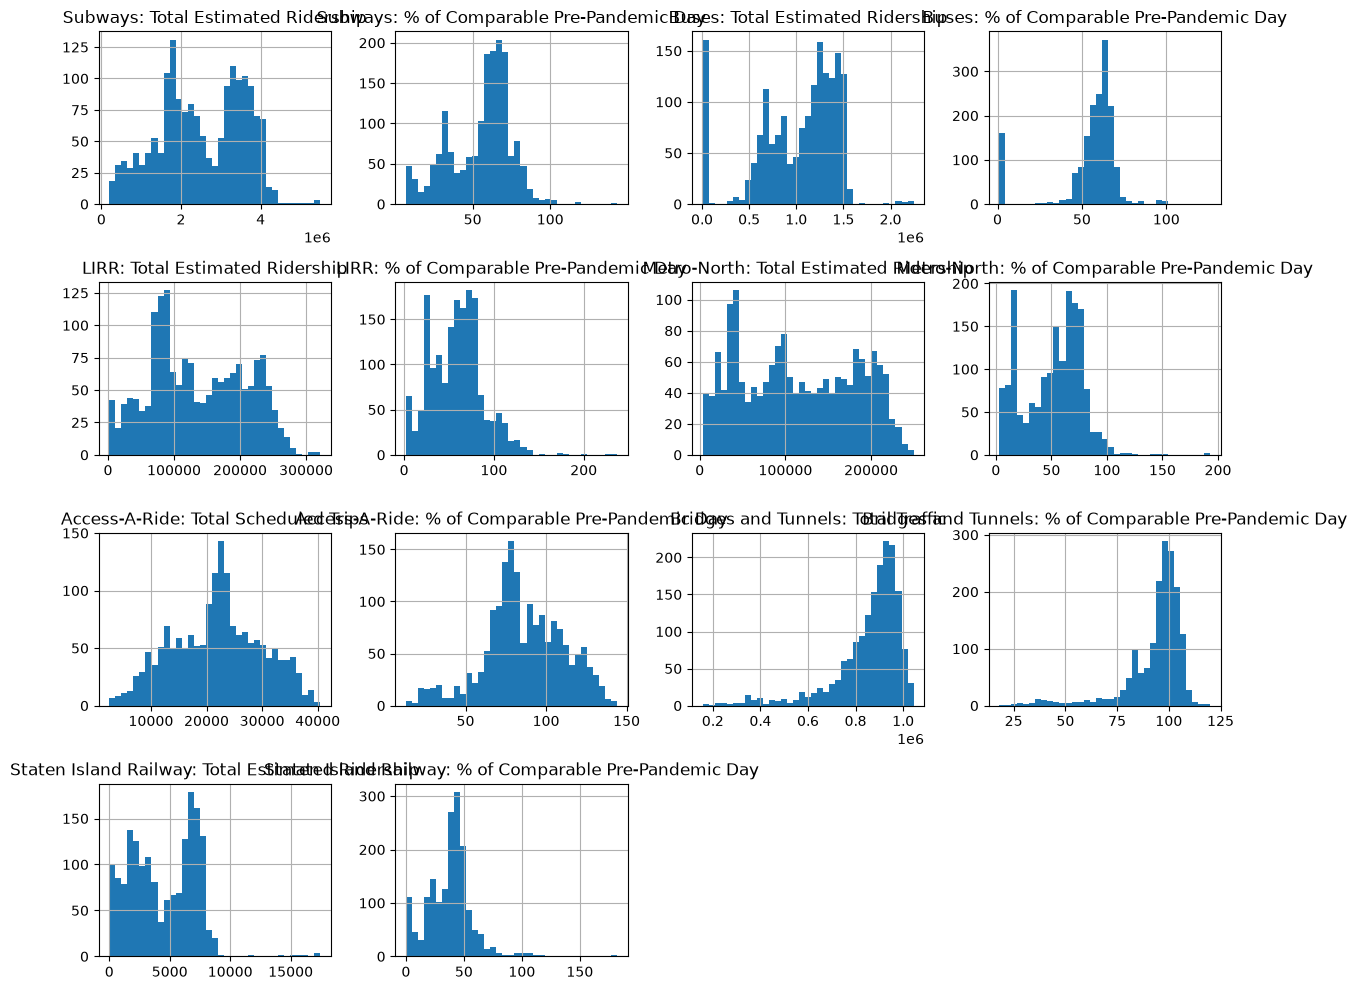

In [8]:
df.hist(figsize=(12,10),bins=35)
plt.tight_layout()
plt.show()

In [9]:
print("Start Date : ",df['Date'].min())
print("End Date : ",df['Date'].max())

Start Date :  2020-03-01
End Date :  2024-10-31



## EDA Findings

1. The dataset contains 1,706 records and 15 columns.
2. The dataset covers March 2020 to October 2024.
3. The Date column is currently stored as an object.
4. All other columns contain numerical data.
5. Missing values: 0.
6. Duplicate records: 0.
7. Duplicate dates: 0.

### Initial Observations
- The dataset contains multiple transportation systems.
- Ridership and traffic values vary across transportation systems.
- Pre-pandemic comparison percentages provide an additional measure of recovery.

### Potential Data Preparation Issues
- Convert Date into datetime format.
- Investigate zero values.
- Validate numerical columns.


In [10]:
df_cleaned = df.copy()

In [11]:
df_cleaned['Date'] = pd.to_datetime(df_cleaned['Date'], errors='coerce', format='%Y-%m-%d')
df_cleaned["Date"].dtype

dtype('<M8[ns]')

In [12]:
df_cleaned.isnull().sum()

Date                                                       0
Subways: Total Estimated Ridership                         0
Subways: % of Comparable Pre-Pandemic Day                  0
Buses: Total Estimated Ridership                           0
Buses: % of Comparable Pre-Pandemic Day                    0
LIRR: Total Estimated Ridership                            0
LIRR: % of Comparable Pre-Pandemic Day                     0
Metro-North: Total Estimated Ridership                     0
Metro-North: % of Comparable Pre-Pandemic Day              0
Access-A-Ride: Total Scheduled Trips                       0
Access-A-Ride: % of Comparable Pre-Pandemic Day            0
Bridges and Tunnels: Total Traffic                         0
Bridges and Tunnels: % of Comparable Pre-Pandemic Day      0
Staten Island Railway: Total Estimated Ridership           0
Staten Island Railway: % of Comparable Pre-Pandemic Day    0
dtype: int64

In [13]:
df_cleaned.duplicated().sum()

np.int64(0)

In [14]:
numeric_cols = df_cleaned.select_dtypes(include='number').columns

(df_cleaned[numeric_cols] < 0).sum()

Subways: Total Estimated Ridership                         0
Subways: % of Comparable Pre-Pandemic Day                  0
Buses: Total Estimated Ridership                           0
Buses: % of Comparable Pre-Pandemic Day                    0
LIRR: Total Estimated Ridership                            0
LIRR: % of Comparable Pre-Pandemic Day                     0
Metro-North: Total Estimated Ridership                     0
Metro-North: % of Comparable Pre-Pandemic Day              0
Access-A-Ride: Total Scheduled Trips                       0
Access-A-Ride: % of Comparable Pre-Pandemic Day            0
Bridges and Tunnels: Total Traffic                         0
Bridges and Tunnels: % of Comparable Pre-Pandemic Day      0
Staten Island Railway: Total Estimated Ridership           0
Staten Island Railway: % of Comparable Pre-Pandemic Day    0
dtype: int64

In [15]:
(df_cleaned[numeric_cols]==0).sum()

Subways: Total Estimated Ridership                          0
Subways: % of Comparable Pre-Pandemic Day                   0
Buses: Total Estimated Ridership                            0
Buses: % of Comparable Pre-Pandemic Day                     0
LIRR: Total Estimated Ridership                             0
LIRR: % of Comparable Pre-Pandemic Day                      0
Metro-North: Total Estimated Ridership                      0
Metro-North: % of Comparable Pre-Pandemic Day               0
Access-A-Ride: Total Scheduled Trips                        0
Access-A-Ride: % of Comparable Pre-Pandemic Day             0
Bridges and Tunnels: Total Traffic                          0
Bridges and Tunnels: % of Comparable Pre-Pandemic Day       0
Staten Island Railway: Total Estimated Ridership           32
Staten Island Railway: % of Comparable Pre-Pandemic Day    54
dtype: int64

In [16]:
df_cleaned=df_cleaned.sort_values(by='Date').reset_index(drop=True)

In [17]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1706 entries, 0 to 1705
Data columns (total 15 columns):
 #   Column                                                   Non-Null Count  Dtype         
---  ------                                                   --------------  -----         
 0   Date                                                     1706 non-null   datetime64[ns]
 1   Subways: Total Estimated Ridership                       1706 non-null   int64         
 2   Subways: % of Comparable Pre-Pandemic Day                1706 non-null   int64         
 3   Buses: Total Estimated Ridership                         1706 non-null   int64         
 4   Buses: % of Comparable Pre-Pandemic Day                  1706 non-null   int64         
 5   LIRR: Total Estimated Ridership                          1706 non-null   int64         
 6   LIRR: % of Comparable Pre-Pandemic Day                   1706 non-null   int64         
 7   Metro-North: Total Estimated Ridership             

In [18]:
print("The Final Shape is :", df_cleaned.shape)
print("The Missing Values is:", df_cleaned.isnull().sum().sum())
print("The Duplicate Rows is:", df_cleaned.duplicated().sum())

print("The Duplicate Dates is:", df_cleaned['Date'].duplicated().sum())

The Final Shape is : (1706, 15)
The Missing Values is: 0
The Duplicate Rows is: 0
The Duplicate Dates is: 0


In [19]:
print("The Original Dataset:", df.shape)
print("The Cleaned Dataset:", df_cleaned.shape)

print("Missing Values:", df_cleaned.isnull().sum().sum())
print("Duplicate Rows:", df_cleaned.duplicated().sum())
print("Duplicate Dates:", df_cleaned['Date'].duplicated().sum())

print("Date Type:", df_cleaned['Date'].dtype)
print("Start Date:", df_cleaned['Date'].min())
print("End Date:", df_cleaned['Date'].max())

The Original Dataset: (1706, 15)
The Cleaned Dataset: (1706, 15)
Missing Values: 0
Duplicate Rows: 0
Duplicate Dates: 0
Date Type: datetime64[ns]
Start Date: 2020-03-01 00:00:00
End Date: 2024-10-31 00:00:00


In [20]:
df_cleaned.to_csv(CLEANED_DATA_PATH, index=False)
print(f"Cleaned dataset written to: {display_path(CLEANED_DATA_PATH)}")


Cleaned dataset written to: WEEK ONE/MTA_Daily_Ridership_Cleaned.csv


In [21]:

transport_config = [
    ("Subways", "Subways: Total Estimated Ridership",
     "Subways: % of Comparable Pre-Pandemic Day",
     "Estimated Ridership"),

    ("Buses", "Buses: Total Estimated Ridership",
     "Buses: % of Comparable Pre-Pandemic Day",
     "Estimated Ridership"),

    ("LIRR", "LIRR: Total Estimated Ridership",
     "LIRR: % of Comparable Pre-Pandemic Day",
     "Estimated Ridership"),

    ("Metro-North", "Metro-North: Total Estimated Ridership",
     "Metro-North: % of Comparable Pre-Pandemic Day",
     "Estimated Ridership"),

    ("Access-A-Ride", "Access-A-Ride: Total Scheduled Trips",
     "Access-A-Ride: % of Comparable Pre-Pandemic Day",
     "Scheduled Trips"),

    ("Bridges and Tunnels", "Bridges and Tunnels: Total Traffic",
     "Bridges and Tunnels: % of Comparable Pre-Pandemic Day",
     "Traffic"),

    ("Staten Island Railway",
     "Staten Island Railway: Total Estimated Ridership",
     "Staten Island Railway: % of Comparable Pre-Pandemic Day",
     "Estimated Ridership")
]

dim_transportation = pd.DataFrame([
    {
        "transport_id": i + 1,
        "transport_name": item[0],
        "activity_measure": item[3]
    }
    for i, item in enumerate(transport_config)
])

dim_date = pd.DataFrame({
    "date_key": df_cleaned["Date"]
})

dim_date["year"] = dim_date["date_key"].dt.year
dim_date["month"] = dim_date["date_key"].dt.month
dim_date["day"] = dim_date["date_key"].dt.day
dim_date["day_name"] = dim_date["date_key"].dt.day_name()


In [22]:
print(dim_date.shape)
print(dim_transportation.shape)

(1706, 5)
(7, 3)


In [23]:
fact_parts = []
for i, item in enumerate(transport_config):

    name, activity, percentage, measure = item

    temp = df_cleaned[["Date", activity, percentage]].copy()
    temp.columns = [
        "date_key",
        "activity_value",
        "recovery_percentage"
    ]

    temp["transport_id"] = i + 1

    fact_parts.append(temp)

fact_daily_metrics = pd.concat(fact_parts, ignore_index=True)
fact_daily_metrics.head()


,date_key,activity_value,recovery_percentage,transport_id
0,2020-03-01,2212965,97,1
1,2020-03-02,5329915,96,1
2,2020-03-03,5481103,98,1
3,2020-03-04,5498809,99,1
4,2020-03-05,5496453,99,1


In [24]:
print("the fact Table Shape:", fact_daily_metrics.shape)

print("\nmissing Values:")
print(fact_daily_metrics.isnull().sum())

print("\nFact Table Preview:")
display(fact_daily_metrics.head(10))

the fact Table Shape: (11942, 4)

missing Values:
date_key               0
activity_value         0
recovery_percentage    0
transport_id           0
dtype: int64

Fact Table Preview:


,date_key,activity_value,recovery_percentage,transport_id
0,2020-03-01,2212965,97,1
1,2020-03-02,5329915,96,1
2,2020-03-03,5481103,98,1
3,2020-03-04,5498809,99,1
4,2020-03-05,5496453,99,1
5,2020-03-06,5189447,93,1
6,2020-03-07,2814637,92,1
7,2020-03-08,2120656,93,1
8,2020-03-09,4973513,89,1
9,2020-03-10,4867818,87,1


## Exporting the Tables from Python

In [25]:
dim_date.to_csv(DATABASE_DIR / "dim_date.csv", index=False)
dim_transportation.to_csv(DATABASE_DIR / "dim_transportation.csv", index=False)
fact_daily_metrics.to_csv(DATABASE_DIR / "fact_daily_metrics.csv", index=False)

print(f"Dimension and fact CSVs exported to: {display_path(DATABASE_DIR)}")


Dimension and fact CSVs exported to: WEEK ONE/database


------------------------------------------------------------------------------------------------------------------------------------------

## Matplotlib visualizations

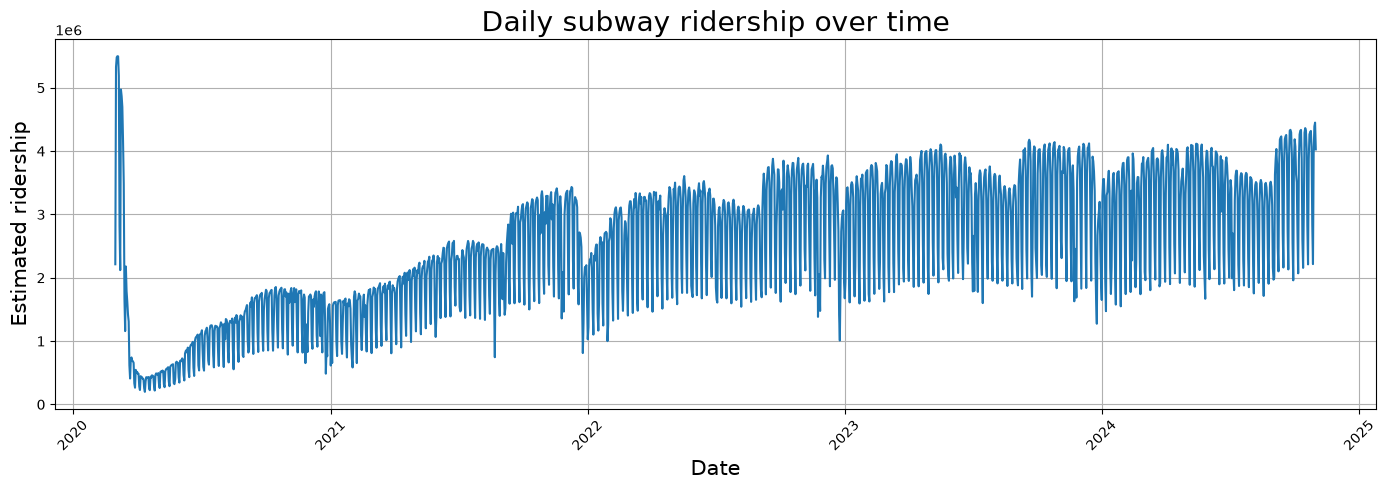

In [26]:
plt.figure(figsize=(14, 5))
plt.plot(df_cleaned["Date"],df_cleaned["Subways: Total Estimated Ridership"])
plt.title("Daily subway ridership over time",fontsize=20)
plt.xlabel("Date",fontsize=15)
plt.ylabel("Estimated ridership", fontsize=15)
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

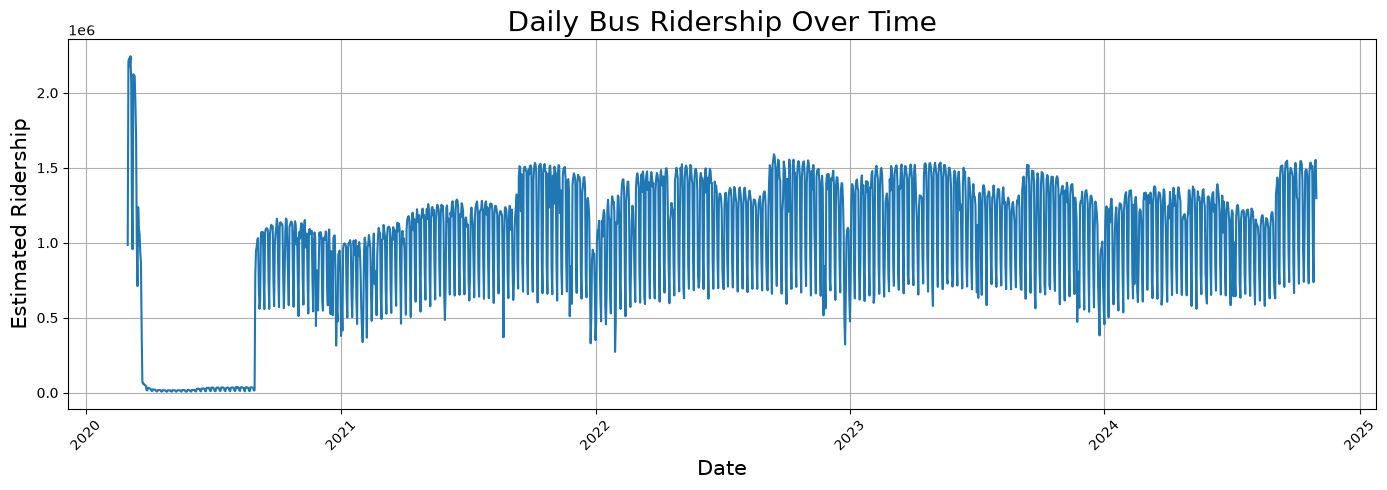

In [27]:
plt.figure(figsize=(14, 5))
plt.plot(df_cleaned["Date"],df_cleaned["Buses: Total Estimated Ridership"])

plt.title("Daily Bus Ridership Over Time", fontsize=20)
plt.xlabel("Date", fontsize=15)
plt.ylabel("Estimated Ridership", fontsize=15)
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()